# Warm Start Share of the Slowest Calls

Companion to `02_cold_impact.ipynb`. That notebook's cold factor (CF) is a *ratio* between the
warm-only and all-calls latency at a percentile, and its headline finding is that the ratio
shrinks back toward 1 above roughly p99.99 -- implying cold starts stop dominating the very
extreme tail. This notebook restates that same finding as a direct, quotable statement instead of
a ratio: for each provider, of the **X% slowest calls** in the `warmstart` experiment (ranked by
`http_req_waiting`), what share were actually **warm** (`cold_starts = 0`) rather than cold?

Uses the same dataset and provider/percentile conventions as `02_cold_impact.ipynb`
(`../data.db`, `experiment = 'warmstart'`, no `cold_starts` filter -- i.e. traffic as observed,
cold starts included). Produces `../figures/warm-share-of-slowest.pdf` plus a per-provider table.

Two adjustments versus a naive percentile sweep:

- **Fastly (FEC) is left out of the plot.** ~99% of *all* its warmstart calls (not just the tail)
  report `cold_starts = 1`, so its warm-share sits near 0% everywhere -- a data/instrumentation
  quirk for that provider, not a tail-latency finding. It's still in the table for transparency.
- **Each curve stops once fewer than 30 calls back a point**, instead of running out to p100
  (which is always exactly one call). 30 has no formal justification beyond being a common
  rule-of-thumb floor for a stable proportion estimate -- it also happens to be the low end of
  the call-count range the paper's own p99.99 discussion already cites, so it isn't introducing a
  new standard. Where each curve should stop is ultimately a judgment call; adjust
  `MIN_N_FOR_CURVE` in the compute cell if a different cutoff reads better for the paper.

The table (not subject to that cutoff -- its `Slowest N` column already makes the sample size
behind every row explicit) runs from p80 to p100: 5-percentage-point steps up to p95, then the
same 0.05-point cadence as the CF table starting at p97 (there is deliberately no row between p95
and p97 -- that gap is the coarse-to-fine transition).


In [1]:
import pandas as pd
import numpy as np
import sqlite3
import seaborn as sns
import matplotlib
matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt

cnx = sqlite3.connect('../data.db')
try:
    cnx.execute('''
            CREATE INDEX IF NOT EXISTS idx_elasticity_lookup
            ON data (experiment, provider, date_time, language, cpu, memory, timestamp)
    ''')
    cnx.commit()
    print("Index created/verified")
except Exception as e:
    print(f"Index creation note: {e}")

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]

label_map = {
    "google": "GCF",
    "awsX86": "AWS (X86)",
    "awsARM": "AWS (ARM)",
    "oracleX86": "OCF (X86)",
    "oracleARM": "OCF (ARM)",
    "deno": "DD",
    "cloudflare": "CW",
    "flyio": "Fly.io",
    "fastly": "Fastly",
}

def load_calls(provider: str) -> pd.DataFrame:
    """All warmstart-experiment calls for a provider: latency plus the cold-start flag.

    Unfiltered (like `load_warmstart(..., mode='all')` in 02_cold_impact.ipynb) so this reflects
    traffic as observed, with naturally occurring cold starts included.
    """
    query = """
        SELECT http_req_waiting, cold_starts
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    df = pd.read_sql_query(query, cnx, params=[provider])
    df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
    df["cold_starts"] = pd.to_numeric(df["cold_starts"], errors="coerce")
    df = df.dropna(subset=["http_req_waiting", "cold_starts"])
    df = df[df["http_req_waiting"] > 0]
    return df


Index created/verified


In [2]:
# For each provider: at every percentile threshold, what share of the calls at or above it
# (i.e. the slowest (100 - percentile)% of calls) were warm (cold_starts == 0)?

# Dense grid for the plotted curve (same convention as 02_cold_impact.ipynb's CF curve).
percentiles = np.linspace(0.80, 1.00, 10000)

# Table grid: coarse 5-point steps from p80 to p95, then the CF table's fine 0.05-point cadence
# starting at p97 (no row between p95 and p97 -- that gap is the coarse-to-fine transition).
table_percentiles = np.concatenate([
    np.array([0.80, 0.85, 0.90, 0.95]),
    np.linspace(0.97, 1.00, 61),  # p97.00, p97.05, ..., p100.00
])

rows_curve = []
rows_table = []

baseline_cold_pct = {}  # provider -> overall cold-start rate (%), used by the enrichment section below

for provider in providers:
    df = load_calls(provider)
    if df.empty:
        continue

    latency = df["http_req_waiting"].to_numpy()
    is_warm = (df["cold_starts"] == 0).to_numpy()
    baseline_cold_pct[provider] = float((~is_warm).mean() * 100.0)

    def warm_share_above(threshold: float) -> tuple[float, int]:
        """% of calls with latency >= threshold that are warm, and how many calls that is."""
        mask = latency >= threshold
        n = int(mask.sum())
        if n == 0:
            return float("nan"), 0
        return float(is_warm[mask].mean() * 100.0), n

    thresholds = df["http_req_waiting"].quantile(percentiles).to_numpy()
    for p, thr in zip(percentiles, thresholds):
        share, n = warm_share_above(thr)
        rows_curve.append({"provider": provider, "percentile": float(p) * 100.0, "pct_warm": share, "n": n})

    thresholds_tbl = df["http_req_waiting"].quantile(table_percentiles).to_numpy()
    for p, thr in zip(table_percentiles, thresholds_tbl):
        share, n = warm_share_above(thr)
        rows_table.append({
            "Provider": label_map.get(provider, provider),
            "Percentile": round(p * 100.0, 2),
            "Top %": round(100.0 - p * 100.0, 2),
            "Slowest N": n,
            "Warm (%)": share,
            "Cold (%)": (100.0 - share) if not np.isnan(share) else float("nan"),
        })

df_curve = pd.DataFrame(rows_curve).dropna(subset=["pct_warm"])
df_table = pd.DataFrame(rows_table)

# Curves get noisy -- and eventually meaningless, since p100 is always exactly one call -- once
# too few calls back a point. No formal test for "enough" here; 30 is a common rule-of-thumb
# floor for a stable proportion estimate, and it's also the low end of the call-count range the
# paper's own p99.99 discussion already cites as the practical sample-size floor at these
# percentiles. Only the plotted curve is truncated; the table keeps every row (with its N).
MIN_N_FOR_CURVE = 30
df_curve_plot = df_curve[df_curve["n"] >= MIN_N_FOR_CURVE].copy()


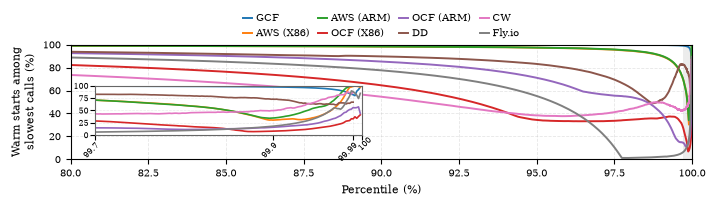

In [3]:
# Line plot: warm-start share vs percentile threshold (same p80..p100 range as the CF plot)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Paper-friendly styling (ACM Middleware 2-column format), matching 02_cold_impact.ipynb.
plt.rcParams.update({
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'font.family': 'serif',
})

# Fastly (FEC) is excluded from the plot: ~99% of *all* its warmstart calls report
# cold_starts=1 (not just the tail), so its warm-share sits near 0% everywhere -- a data /
# instrumentation quirk for that provider, not a tail-latency finding. It stays in the table.
EXCLUDED_FROM_PLOT = {"fastly"}

if df_curve_plot.empty:
    print("No data to plot warm-share vs percentile.")
else:
    providers_in_plot = [
        p for p in providers
        if p not in EXCLUDED_FROM_PLOT and p in set(df_curve_plot["provider"])
    ]
    palette = sns.color_palette("tab10", n_colors=len(providers_in_plot))
    palette_map = dict(zip(providers_in_plot, palette))

    # ACM full-page (two-column) width is ~7.0in
    fig, ax = plt.subplots(figsize=(7.0, 2.35))

    for provider in providers_in_plot:
        # Stops wherever the call count backing a point drops below MIN_N_FOR_CURVE, rather
        # than running all the way to p100 (always a single call).
        df_p = df_curve_plot[df_curve_plot["provider"] == provider].sort_values("percentile")
        ax.plot(
            df_p["percentile"],
            df_p["pct_warm"],
            linewidth=1.4,
            color=palette_map[provider],
            label=label_map.get(provider, provider),
        )

    ax.set_xlabel("Percentile (%)")
    ax.set_ylabel("Warm starts among\nslowest calls (%)")
    ax.set_xlim(80, 100)
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle="--", alpha=0.30, linewidth=0.6)

    ncol = min(4, max(1, int(np.ceil(len(providers_in_plot) / 2))))
    ax.legend(
        title=None,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=ncol,
        frameon=False,
        handlelength=0.9,
        columnspacing=0.9,
        handletextpad=0.4,
        borderaxespad=0.0,
    )

    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

    # Mark the zoomed region on the main plot. Unlike the CF plot's near-flat baseline, these
    # curves move across the full y-range everywhere, so mark_inset's connector lines cut across
    # real data and read as clutter -- a plain shaded band is a cleaner pointer to p99.7-100.
    ax.axvspan(99.7, 100, color="0.4", alpha=0.12, linewidth=0)

    # Zoom inset on the extreme tail (p99.7-100). Placed lower-left: unlike the CF plot, most
    # curves here sit near 100% at p80 (top-left), so the empty corner is bottom-left instead.
    axins = inset_axes(
        ax,
        width="43%",
        height="43%",
        loc="lower left",
        borderpad=2.5,
    )
    for provider in providers_in_plot:
        df_p = df_curve_plot[df_curve_plot["provider"] == provider].sort_values("percentile")
        axins.plot(
            df_p["percentile"],
            df_p["pct_warm"],
            linewidth=1.2,
            color=palette_map[provider],
        )

    axins.set_xlim(99.7, 100)
    axins.set_ylim(0, 100)
    axins.grid(True, linestyle="--", alpha=0.25, linewidth=0.5)
    axins.set_xticks([99.7, 99.9, 99.99, 100])
    axins.set_xticklabels(
        ["99.7", "99.9", "99.99", "100"],
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )
    for label in axins.get_xticklabels():
        if label.get_text() == "100":
            label.set_ha("center")

    axins.set_yticks([0, 25, 50, 75, 100])
    axins.tick_params(axis='both', labelsize=6, pad=1)
    axins.set_xlabel("")
    axins.set_ylabel("")
    for spine in axins.spines.values():
        spine.set_edgecolor("0.4")
        spine.set_linewidth(0.8)

    fig.savefig("../figures/warm-share-of-slowest.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [4]:
# Table: "of the slowest N calls, what share were warm?" per provider, p80..p100
if df_table.empty:
    print("No data for the summary table.")
else:
    print("\n" + "=" * 80)
    print("Warm-start share among the slowest calls, per percentile")
    print("(p80, p85, p90, p95, then p97.00..p100.00 in 0.05-point steps)")
    print("=" * 80)

    for prov in df_table["Provider"].unique():
        print(f"\n--- {prov} ---")
        sub_df = df_table[df_table["Provider"] == prov].drop(columns=["Provider"])
        print(sub_df.round(2).to_string(index=False))

    print("\n" + "=" * 80 + "\n")



Warm-start share among the slowest calls, per percentile
(p80, p85, p90, p95, then p97.00..p100.00 in 0.05-point steps)

--- GCF ---
 Percentile  Top %  Slowest N  Warm (%)  Cold (%)
      80.00  20.00     383892     99.98      0.02
      85.00  15.00     287919     99.97      0.03
      90.00  10.00     191946     99.95      0.05
      95.00   5.00      95973     99.91      0.09
      97.00   3.00      57584     99.87      0.13
      97.05   2.95      56625     99.86      0.14
      97.10   2.90      55665     99.86      0.14
      97.15   2.85      54705     99.86      0.14
      97.20   2.80      53745     99.86      0.14
      97.25   2.75      52786     99.87      0.13
      97.30   2.70      51826     99.87      0.13
      97.35   2.65      50866     99.86      0.14
      97.40   2.60      49906     99.86      0.14
      97.45   2.55      48947     99.86      0.14
      97.50   2.50      47987     99.86      0.14
      97.55   2.45      47027     99.87      0.13
      97.60   2.

## Cold-Start Enrichment Relative to Each Provider's Baseline

The warm-share view above mixes two different things per provider: how common cold starts are
overall, and how concentrated they are specifically in the tail. That makes the curves hard to
compare across providers -- a provider with a high baseline cold-start rate will show a lower
warm-share in the tail even if cold starts are no more (or less) concentrated there than usual.

This section normalizes for that: for each provider,

```
enrichment(X%) = P(cold | among the slowest X% calls) / P(cold overall)
```

A ratio of 1 means the tail's cold/warm mix just matches that provider's normal traffic. Above 1
means cold starts are over-represented in the tail; below 1 would mean cold starts are
under-represented there (the strongest possible form of "warm dominates the tail").

**Empirically, the ratio never drops below roughly 1 for any provider between p80 and p100** --
cold starts stay at least 2-5x over-represented throughout, and that over-representation grows
(not shrinks) deeper into the tail. This complicates a naive "warm dominates the extreme tail"
reading: cold starts make up a small fraction of the tail's raw call count (since they're rare to
begin with, which is what the warm-share plot above shows), but they remain -- increasingly --
disproportionately likely to appear there relative to their own baseline rate.

Two plots, both excluding Fastly (FEC): its `cold_starts` field reports cold for ~99% of *all*
traffic (see the note above), so its enrichment ratio is a degenerate flat 1.0 and adds nothing.

- **Linear-axis plot**: also excludes GCF. Even without GCF, AWS X86 and AWS ARM spike to ~330x
  around p99.9 -- backed by ~1,600-2,000 calls, not truncation noise, so a real finding rather
  than a low-baseline artifact. The main axis shows that spike at true scale; a zoomed inset over
  p80-97 gives the more legible comparison among the rest of the range.
- **Log-axis plot**: adds GCF back in. Its baseline cold-start rate is so low (0.005%) that its
  ratio reaches ~3,700x at the far tail -- only a log axis keeps that on the same plot as
  everyone else.


In [5]:
# Derive the enrichment ratio directly from the warm-share curve computed above: no new query
# needed, since pct_cold = 100 - pct_warm and the per-provider baseline was captured in the loop.
df_enrich_plot = df_curve_plot.copy()
df_enrich_plot["baseline_cold_pct"] = df_enrich_plot["provider"].map(baseline_cold_pct)
df_enrich_plot["pct_cold"] = 100.0 - df_enrich_plot["pct_warm"]
df_enrich_plot["cold_enrichment"] = df_enrich_plot["pct_cold"] / df_enrich_plot["baseline_cold_pct"]


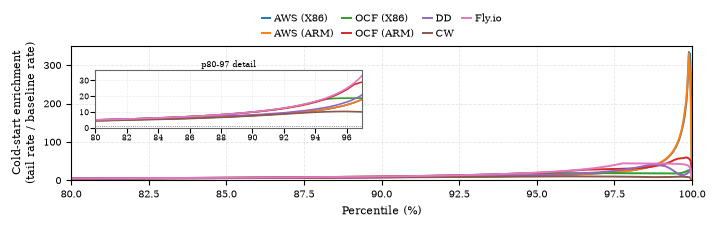

In [6]:
# Plot: cold-start enrichment, linear axis, excludes GCF and Fastly (FEC).
EXCLUDED_LINEAR = {"google", "fastly"}

if df_enrich_plot.empty:
    print("No data to plot cold-start enrichment (linear).")
else:
    providers_linear = [
        p for p in providers
        if p not in EXCLUDED_LINEAR and p in set(df_enrich_plot["provider"])
    ]
    palette = sns.color_palette("tab10", n_colors=len(providers_linear))
    palette_map = dict(zip(providers_linear, palette))

    fig, ax = plt.subplots(figsize=(7.0, 2.6))

    for provider in providers_linear:
        df_p = df_enrich_plot[df_enrich_plot["provider"] == provider].sort_values("percentile")
        ax.plot(
            df_p["percentile"],
            df_p["cold_enrichment"],
            linewidth=1.4,
            color=palette_map[provider],
            label=label_map.get(provider, provider),
        )

    ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":", alpha=0.6)
    ax.set_xlabel("Percentile (%)")
    ax.set_ylabel("Cold-start enrichment\n(tail rate / baseline rate)")
    ax.set_xlim(80, 100)
    y_max = df_enrich_plot[df_enrich_plot["provider"].isin(providers_linear)]["cold_enrichment"].max()
    ax.set_ylim(0, y_max * 1.05)
    ax.grid(True, linestyle="--", alpha=0.30, linewidth=0.6)

    ncol = min(4, max(1, int(np.ceil(len(providers_linear) / 2))))
    ax.legend(
        title=None,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=ncol,
        frameon=False,
        handlelength=0.9,
        columnspacing=0.9,
        handletextpad=0.4,
        borderaxespad=0.0,
    )

    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

    # AWS X86/ARM's spike (~p99.9) dwarfs everyone else on this axis, so the interesting
    # cross-provider comparison happens below p97 -- zoom on that range instead of the tail.
    axins = inset_axes(
        ax,
        width="43%",
        height="43%",
        loc="upper left",
        borderpad=2.5,
    )
    for provider in providers_linear:
        df_p = df_enrich_plot[
            (df_enrich_plot["provider"] == provider) & (df_enrich_plot["percentile"] <= 97)
        ].sort_values("percentile")
        axins.plot(
            df_p["percentile"],
            df_p["cold_enrichment"],
            linewidth=1.2,
            color=palette_map[provider],
        )
    axins.axhline(1.0, color="black", linewidth=0.6, linestyle=":", alpha=0.6)
    axins.set_xlim(80, 97)
    y_max_inset = df_enrich_plot[
        (df_enrich_plot["provider"].isin(providers_linear)) & (df_enrich_plot["percentile"] <= 97)
    ]["cold_enrichment"].max()
    axins.set_ylim(0, y_max_inset * 1.1)
    axins.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=4, integer=True))
    axins.grid(True, linestyle="--", alpha=0.25, linewidth=0.5)
    axins.tick_params(axis="both", labelsize=6, pad=1)
    axins.set_xlabel("")
    axins.set_ylabel("")
    axins.set_title("p80-97 detail", fontsize=6, pad=2)
    for spine in axins.spines.values():
        spine.set_edgecolor("0.4")
        spine.set_linewidth(0.8)

    fig.savefig("../figures/cold-enrichment-linear.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


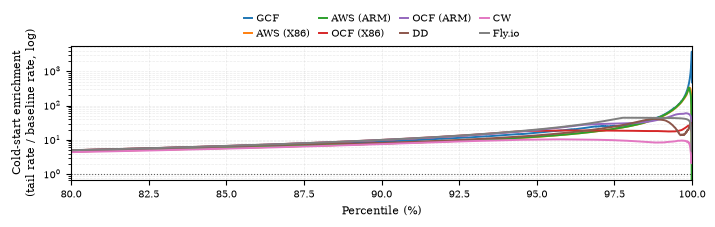

In [7]:
# Plot: cold-start enrichment, log axis, adds GCF back in (still excludes Fastly/FEC).
EXCLUDED_LOG = {"fastly"}

if df_enrich_plot.empty:
    print("No data to plot cold-start enrichment (log).")
else:
    providers_log = [
        p for p in providers
        if p not in EXCLUDED_LOG and p in set(df_enrich_plot["provider"])
    ]
    palette = sns.color_palette("tab10", n_colors=len(providers_log))
    palette_map = dict(zip(providers_log, palette))

    fig, ax = plt.subplots(figsize=(7.0, 2.6))

    for provider in providers_log:
        df_p = df_enrich_plot[df_enrich_plot["provider"] == provider].sort_values("percentile")
        ax.plot(
            df_p["percentile"],
            df_p["cold_enrichment"],
            linewidth=1.4,
            color=palette_map[provider],
            label=label_map.get(provider, provider),
        )

    ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":", alpha=0.6)
    ax.set_yscale("log")
    ax.set_xlabel("Percentile (%)")
    ax.set_ylabel("Cold-start enrichment\n(tail rate / baseline rate, log)")
    ax.set_xlim(80, 100)
    ax.grid(True, which="both", linestyle="--", alpha=0.25, linewidth=0.5)

    ncol = min(4, max(1, int(np.ceil(len(providers_log) / 2))))
    ax.legend(
        title=None,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=ncol,
        frameon=False,
        handlelength=0.9,
        columnspacing=0.9,
        handletextpad=0.4,
        borderaxespad=0.0,
    )

    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

    fig.savefig("../figures/cold-enrichment-log.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [8]:
# Table: cold-start enrichment ratio, alongside the same warm/cold breakdown as the table above.
# Reuses df_table (all providers, unfiltered by MIN_N_FOR_CURVE -- same rationale as before: the
# Slowest N column keeps the sample size behind every row explicit).
baseline_cold_pct_by_label = {
    label_map[p]: v for p, v in baseline_cold_pct.items() if p in label_map
}

df_enrich_table = df_table.copy()
df_enrich_table["Baseline Cold (%)"] = df_enrich_table["Provider"].map(baseline_cold_pct_by_label)
df_enrich_table["Cold Enrichment"] = df_enrich_table["Cold (%)"] / df_enrich_table["Baseline Cold (%)"]

if df_enrich_table.empty:
    print("No data for the enrichment table.")
else:
    print("\n" + "=" * 90)
    print("Cold-start enrichment (tail cold-start rate / provider's own overall cold-start rate)")
    print("(p80, p85, p90, p95, then p97.00..p100.00 in 0.05-point steps)")
    print("=" * 90)

    for prov in df_enrich_table["Provider"].unique():
        print(f"\n--- {prov} ---")
        sub_df = df_enrich_table[df_enrich_table["Provider"] == prov].drop(columns=["Provider"])
        print(sub_df.round(2).to_string(index=False))

    print("\n" + "=" * 90 + "\n")



Cold-start enrichment (tail cold-start rate / provider's own overall cold-start rate)
(p80, p85, p90, p95, then p97.00..p100.00 in 0.05-point steps)

--- GCF ---
 Percentile  Top %  Slowest N  Warm (%)  Cold (%)  Baseline Cold (%)  Cold Enrichment
      80.00  20.00     383892     99.98      0.02               0.01             4.57
      85.00  15.00     287919     99.97      0.03               0.01             5.96
      90.00  10.00     191946     99.95      0.05               0.01             8.85
      95.00   5.00      95973     99.91      0.09               0.01            16.15
      97.00   3.00      57584     99.87      0.13               0.01            24.68
      97.05   2.95      56625     99.86      0.14               0.01            25.10
      97.10   2.90      55665     99.86      0.14               0.01            25.53
      97.15   2.85      54705     99.86      0.14               0.01            24.97
      97.20   2.80      53745     99.86      0.14              